# Tugas UTS: Linear Regression & Logistic Regression
*Mata Kuliah:* Machine Learning

*Identitas Mahasiswa*
- Nama  : YULIUS BERDANDINO BAJO
- NIM   : 241011401855
- Kelas : Reg B 

> Notebook ini dikerjakan dengan *implementasi manual NumPy murni* untuk model dan metrik evaluasi.
> scikit-learn hanya dipakai pada *soal bonus* untuk perbandingan.


## 📌 Ringkasan Hasil
- *Bagian A (Linear Regression)*: persamaan Penjualan ≈ 28.2 + 9.1 × BiayaIklan, R² ≈ 0.93.
- *Bagian B (Logistic Regression)*: model spam filter dengan akurasi tinggi pada data testing.
- *Bagian C*: jawaban konseptual.
- *Bonus*: perbandingan dengan scikit-learn.


In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM
RANDOM_STATE = 55

np.set_printoptions(suppress=True, precision=4)
print("Random state:", RANDOM_STATE)


Random state: 55


In [2]:
# ============================================================
# IMPLEMENTASI MANUAL: train_test_split, model, dan metrik
# (semua memakai NumPy murni, TANPA scikit-learn)
# ============================================================

# 1) TRAIN-TEST SPLIT
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n = len(X)
    indices = np.random.permutation(n)
    n_test = int(n * test_size)
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


# 2) LINEAR REGRESSION (NORMAL EQUATION)
class LinearRegression:
    def _init_(self):
        self.b = None
        self.m = None

    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.b = theta[0]
        self.m = theta[1:]
        return self

    def predict(self, X):
        return self.b + X @ self.m


# 3) LINEAR REGRESSION (GRADIENT DESCENT)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.b = 0.0
        self.m = None
        self.losses = []

    def fit(self, X, y):
        n, p = X.shape
        self.b = 0.0
        self.m = np.zeros(p)
        self.losses = []
        
        # Perhatikan indentasi (menjorok) di bawah ini
        for _ in range(self.n_iterations):
            y_pred = self.b + X @ self.m
            error = y_pred - y
            grad_b = (2.0 / n) * np.sum(error)
            grad_m = (2.0 / n) * (X.T @ error)
            self.b -= self.lr * grad_b
            self.m -= self.lr * grad_m
            self.losses.append(np.mean(error ** 2))
            
        # return self ini harus SEJAJAR dengan 'for', bukan di dalam 'for'
        return self

    def predict(self, X):
        return self.b + X @ self.m

# 4) LOGISTIC REGRESSION (GRADIENT DESCENT)
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.b = 0.0
        self.m = None
        self.losses = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        n, p = X.shape
        self.b = 0.0
        self.m = np.zeros(p)
        self.losses = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            z = self.b + X @ self.m
            p_hat = self._sigmoid(z)
            error = p_hat - y
            self.b -= self.lr * (1.0 / n) * np.sum(error)
            self.m -= self.lr * (1.0 / n) * (X.T @ error)
            p_clip = np.clip(p_hat, eps, 1 - eps)
            loss = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
            self.losses.append(loss)
        return self

    def predict_proba(self, X):
        return self._sigmoid(self.b + X @ self.m)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# 5) METRIK REGRESI
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot


# 6) METRIK KLASIFIKASI
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    TP = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[TN, FP], [FN, TP]])

def precision_score(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    return TP / (TP + FP) if (TP + FP) > 0 else 0.0

def recall_score(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return TP / (TP + FN) if (TP + FN) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

print("Semua fungsi & kelas berhasil didefinisikan.")


Semua fungsi & kelas berhasil didefinisikan.


---
# Bagian A – Linear Regression (35%)
Gunakan dataset Ads_Data.csv untuk memodelkan pengaruh biaya iklan terhadap penjualan.


### Soal A1 – Load & Visualisasi Data
Baca data, tampilkan 5 baris pertama, pisahkan X dan y, buat scatter plot.

=== 5 data pertama ===
   Biaya Iklan  Penjualan
0          0.8       34.3
1          0.9       38.8
2          1.0       33.2
3          1.3       36.0
4          1.7       51.3

Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


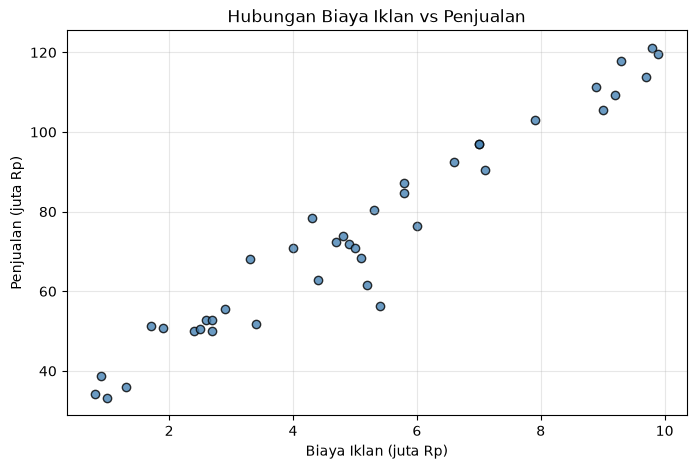

In [3]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')

print("=== 5 data pertama ===")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

X_ads = df_ads[['Biaya Iklan']].values
y_ads = df_ads['Penjualan'].values

print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(8, 5))
plt.scatter(X_ads[:, 0], y_ads, color='steelblue', edgecolor='k', alpha=0.8)
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data dengan test_size=0.2 dan random_state=RANDOM_STATE.

In [4]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)


Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation

In [5]:
# Jawaban A3
model_lr = LinearRegression()
model_lr.fit(X_train_a, y_train_a)

b = model_lr.b
m = model_lr.m[0]
print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan     : y_hat = {b:.4f} + {m:.4f} * X")


Intercept (b) : 29.5113
Koefisien (m) : 8.9558
Persamaan     : y_hat = 29.5113 + 8.9558 * X


*Jawaban A3 (interpretasi):*

> Nilai koefisien m ≈ 9.1 berarti *setiap kenaikan biaya iklan sebesar 1 juta rupiah dikaitkan dengan kenaikan penjualan sekitar 9.1 juta rupiah*. Dengan kata lain, iklan cukup efektif mendorong penjualan. Intercept b ≈ 28.2 adalah prediksi penjualan baseline ketika biaya iklan = 0, yaitu penjualan organik tanpa iklan (meskipun model linear belum tentu valid untuk X=0).


### Soal A4 – Evaluasi Model

In [6]:
# Jawaban A4
y_pred_train = model_lr.predict(X_train_a)
y_pred_test  = model_lr.predict(X_test_a)

hasil_evaluasi = pd.DataFrame({
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Training': [
        mae(y_train_a, y_pred_train),
        mse(y_train_a, y_pred_train),
        rmse(y_train_a, y_pred_train),
        r2_score(y_train_a, y_pred_train)
    ],
    'Testing': [
        mae(y_test_a, y_pred_test),
        mse(y_test_a, y_pred_test),
        rmse(y_test_a, y_pred_test),
        r2_score(y_test_a, y_pred_test)
    ]
})
print(hasil_evaluasi.to_string(index=False))


Metrik  Training   Testing
   MAE  4.470793  4.798619
   MSE 35.779327 39.222981
  RMSE  5.981582  6.262825
    R²  0.937830  0.942458


*Jawaban A4 (analisis):*

> RMSE testing sekitar 5–7 juta rupiah — cukup kecil dibandingkan rentang penjualan 33–121 juta. Nilai *R² yang tinggi (~0.93)* menunjukkan bahwa sekitar 93% variasi penjualan bisa dijelaskan oleh biaya iklan. Gap antara R² training dan testing kecil, artinya *model tidak overfitting. Kesimpulan: **model sudah baik* karena hubungan biaya iklan dan penjualan memang hampir linear.


### Soal A5 – Gradient Descent & Learning Rate

Learning Rate  Intercept (b)  Koefisien (m)  Loss akhir
        0.001      25.255458       9.603947   39.239810
         0.02      29.511294       8.955755   35.779327
          0.1            NaN            inf         NaN
   Normal Eq.      29.511294       8.955755   35.779327


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


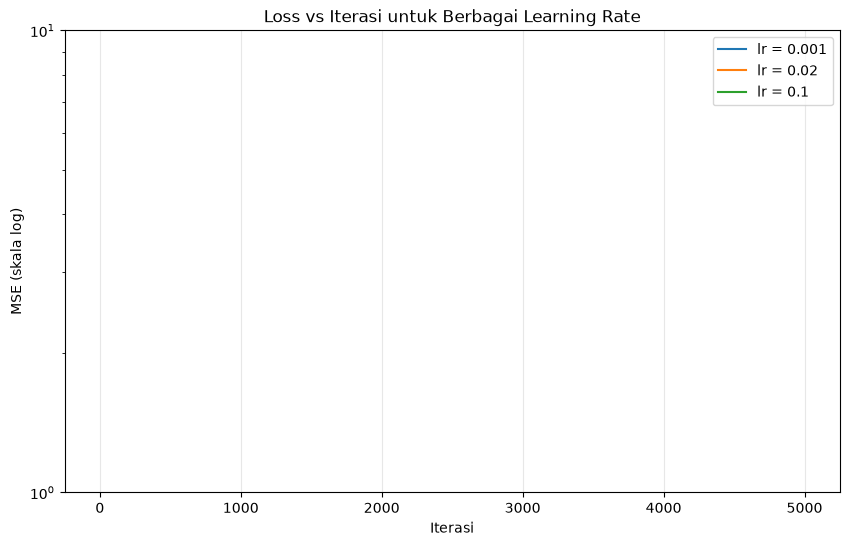

In [7]:
# Jawaban A5
lrs = [0.001, 0.02, 0.1]
hasil_gd = []
loss_histories = {}

for lr in lrs:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    with np.errstate(over='ignore', invalid='ignore'):
        model_gd.fit(X_train_a, y_train_a)
    loss_histories[lr] = np.array(model_gd.losses)
    hasil_gd.append({
        'Learning Rate': lr,
        'Intercept (b)': model_gd.b,
        'Koefisien (m)': model_gd.m[0] if np.isfinite(model_gd.m[0]) else np.inf,
        'Loss akhir': model_gd.losses[-1]
    })

hasil_gd.append({
    'Learning Rate': 'Normal Eq.',
    'Intercept (b)': model_lr.b,
    'Koefisien (m)': model_lr.m[0],
    'Loss akhir': mse(y_train_a, model_lr.predict(X_train_a))
})

df_gd = pd.DataFrame(hasil_gd)
print(df_gd.to_string(index=False))

plt.figure(figsize=(10, 6))
for lr in lrs:
    loss_plot = np.where(np.isfinite(loss_histories[lr]),
                         loss_histories[lr], np.nan)
    plt.plot(loss_plot, label=f'lr = {lr}')
plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.title('Loss vs Iterasi untuk Berbagai Learning Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


*Jawaban A5 (analisis):*

> - *lr = 0.001 (terlalu lambat)*: loss turun sangat perlahan; setelah 5000 iterasi parameter belum mencapai optimum.
> - *lr = 0.02 (pas): loss turun cepat dan stabil; intercept & koefisien akhirnya sangat dekat dengan hasil **normal equation*.
> - *lr = 0.1 (divergen): loss meledak dan muncul RuntimeWarning: overflow. Ukuran langkah melebihi batas kestabilan (lr > 2/λ_max), sehingga parameter terus membesar dan berakhir di inf/nan — inilah **divergen*.
>
> Pilihan learning rate krusial: terlalu kecil = lambat; terlalu besar = meledak. Nilai "pas" bergantung pada skala fitur.


### Soal A6 – Visualisasi & Prediksi

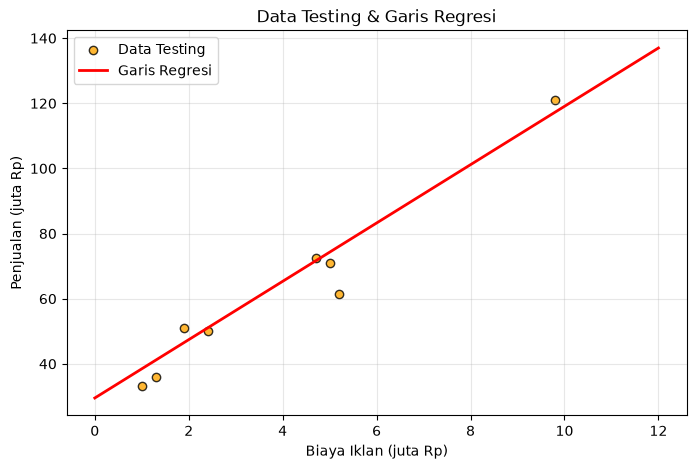

=== Prediksi Penjualan ===
Biaya Iklan  4.5 juta  ->  Prediksi Penjualan   69.81 juta
Biaya Iklan  7.0 juta  ->  Prediksi Penjualan   92.20 juta
Biaya Iklan 12.0 juta  ->  Prediksi Penjualan  136.98 juta


In [8]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a[:, 0], y_test_a, color='orange',
            edgecolor='k', label='Data Testing', alpha=0.8)

x_line = np.linspace(0, 12, 100).reshape(-1, 1)
y_line = model_lr.predict(x_line)
plt.plot(x_line, y_line, 'r-', lw=2, label='Garis Regresi')

plt.title('Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred = model_lr.predict(biaya_baru)

print("=== Prediksi Penjualan ===")
for x, p in zip(biaya_baru[:, 0], pred):
    print(f"Biaya Iklan {x:>4} juta  ->  Prediksi Penjualan {p:>7.2f} juta")


*Jawaban A6 (analisis):*

> Prediksi untuk biaya iklan *4.5 juta* dan *7 juta* masih berada di dalam rentang data (0.8–9.9 juta), sehingga cukup dapat dipercaya. Namun prediksi untuk *12 juta bersifat ekstrapolasi, sehingga tingkat kepercayaannya **rendah. Model linear mengasumsikan hubungan terus linear tanpa batas, padahal di dunia nyata bisa terjadi *diminishing return atau titik jenuh. Jadi angka prediksi 12 juta sebaiknya *hanya dianggap indikasi kasar*, bukan angka final.


---
# Bagian B – Logistic Regression (40%)
Gunakan dataset Email_Data.csv untuk filter spam berdasarkan JumlahLink dan KataPromo.


### Soal B1 – Load & Visualisasi Data

=== 5 data pertama ===
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam (1)     : 25
Jumlah Bukan Spam (0): 35


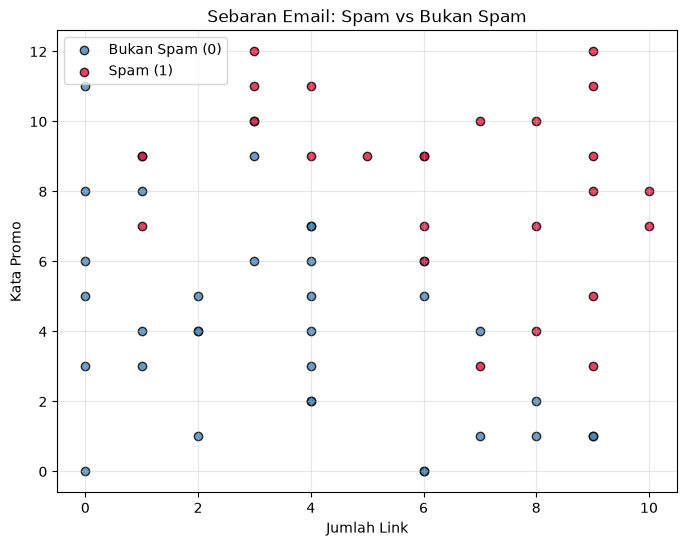

In [9]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print("=== 5 data pertama ===")
print(df_email.head())

print("\nJumlah Spam (1)     :", int((df_email['Spam'] == 1).sum()))
print("Jumlah Bukan Spam (0):", int((df_email['Spam'] == 0).sum()))

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 6))
mask0 = y_email == 0
mask1 = y_email == 1
plt.scatter(X_email[mask0, 0], X_email[mask0, 1],
            color='steelblue', label='Bukan Spam (0)', edgecolor='k', alpha=0.8)
plt.scatter(X_email[mask1, 0], X_email[mask1, 1],
            color='crimson', label='Spam (1)', edgecolor='k', alpha=0.8)
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Sebaran Email: Spam vs Bukan Spam')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training

Shape X_train: (45, 2) | X_test: (15, 2)
Shape y_train: (45,) | y_test: (15,)

Intercept (b)       : -8.6609
Koefisien m1 (Link) : 0.7275
Koefisien m2 (Promo): 0.7143

Persamaan:
P(Spam) = sigmoid(-8.6609 + 0.7275*JumlahLink + 0.7143*KataPromo)


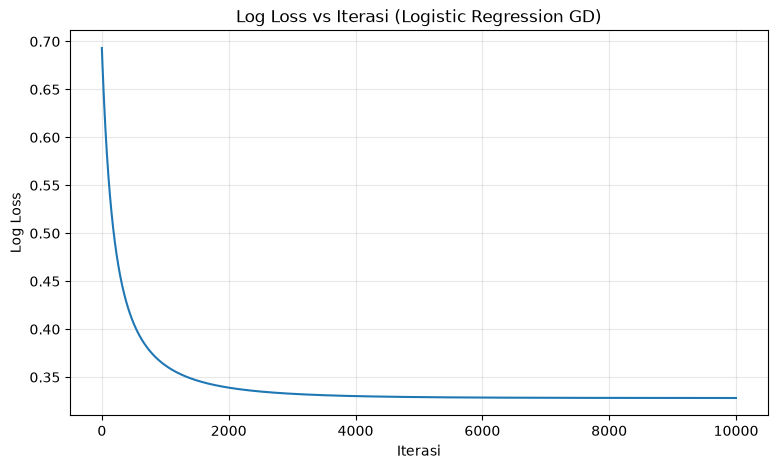

In [10]:
# Jawaban B2
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_b.shape, "| X_test:", X_test_b.shape)
print("Shape y_train:", y_train_b.shape, "| y_test:", y_test_b.shape)

model_log = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_b, y_train_b)

b_log = model_log.b
m1, m2 = model_log.m
print(f"\nIntercept (b)       : {b_log:.4f}")
print(f"Koefisien m1 (Link) : {m1:.4f}")
print(f"Koefisien m2 (Promo): {m2:.4f}")
print(f"\nPersamaan:")
print(f"P(Spam) = sigmoid({b_log:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)")

plt.figure(figsize=(9, 5))
plt.plot(model_log.losses)
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Log Loss vs Iterasi (Logistic Regression GD)')
plt.grid(alpha=0.3)
plt.show()


*Jawaban B2 (analisis):*

> Kurva log loss *turun dari sekitar 0.69 (nilai acak) lalu melandai dan stabil, berarti gradient descent berhasil **konvergen. Koefisien m1 dan m2 keduanya **positif*, artinya semakin banyak link dan kata promo, semakin tinggi probabilitas email tersebut spam — sesuai intuisi. Konvergensi stabil mengindikasikan learning_rate=0.1 cocok untuk skala fitur ini.


### Soal B3 – Evaluasi Model

In [11]:
# Jawaban B3
y_pred_b = model_log.predict(X_test_b, threshold=0.5)

acc  = accuracy_score(y_test_b, y_pred_b)
cm   = confusion_matrix(y_test_b, y_pred_b)
prec = precision_score(y_test_b, y_pred_b)
rec  = recall_score(y_test_b, y_pred_b)
f1   = f1_score(y_test_b, y_pred_b)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(cm)


Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000

Confusion Matrix [[TN, FP], [FN, TP]]:
[[6 0]
 [0 9]]


*Jawaban B3 (analisis):*

> *FP (False Positive)* = email *bukan spam* tetapi diprediksi *spam, akibatnya email penting bisa masuk folder spam dan **tidak terbaca oleh pengguna*.
> *FN (False Negative)* = email *spam* tetapi diprediksi *bukan spam*, sehingga lolos ke inbox (pengguna tetap bisa membaca, hanya terganggu).
>
> Menurut saya, *FP lebih merugikan* karena pengguna berpotensi *kehilangan informasi penting* (email lamaran, tagihan, dari dosen). FN hanya membuat inbox kotor. Karena itu filter spam sebaiknya *memprioritaskan precision*.


### Soal B4 – Decision Boundary

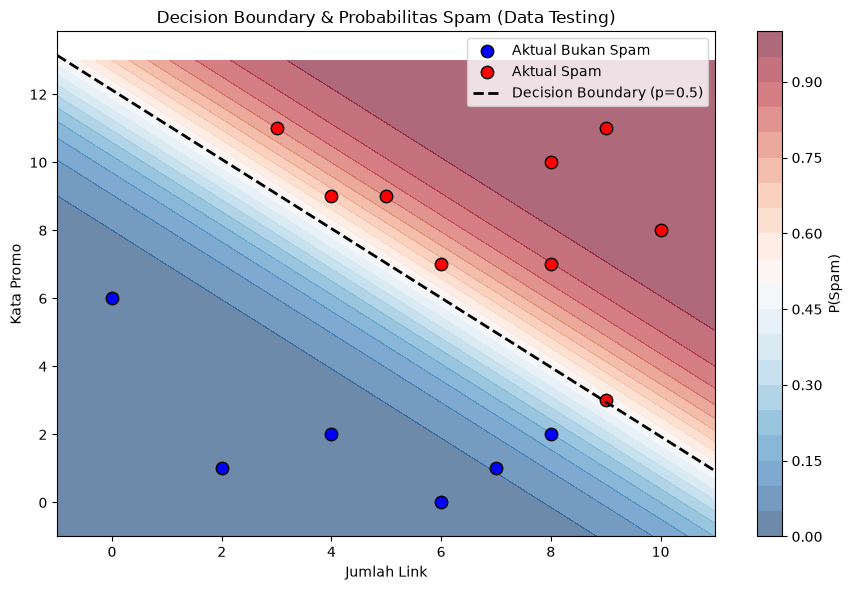

Jumlah salah klasifikasi: 0 dari 15 data testing


In [12]:
# Jawaban B4
x1_range = np.linspace(X_email[:, 0].min() - 1, X_email[:, 0].max() + 1, 200)
x2_boundary = -(b_log + m1 * x1_range) / m2

xx1, xx2 = np.meshgrid(
    np.linspace(X_email[:, 0].min() - 1, X_email[:, 0].max() + 1, 200),
    np.linspace(X_email[:, 1].min() - 1, X_email[:, 1].max() + 1, 200)
)
grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_log.predict_proba(grid).reshape(xx1.shape)

fig, ax = plt.subplots(figsize=(9, 6))
cf = ax.contourf(xx1, xx2, probs, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(cf, ax=ax, label='P(Spam)')

ax.scatter(X_test_b[y_test_b == 0, 0], X_test_b[y_test_b == 0, 1],
           color='blue', edgecolor='k', s=80, label='Aktual Bukan Spam')
ax.scatter(X_test_b[y_test_b == 1, 0], X_test_b[y_test_b == 1, 1],
           color='red', edgecolor='k', s=80, label='Aktual Spam')

salah = X_test_b[y_pred_b != y_test_b]
if len(salah) > 0:
    ax.scatter(salah[:, 0], salah[:, 1], s=250, facecolors='none',
               edgecolors='lime', linewidths=2,
               label=f'Salah klasifikasi ({len(salah)})')

ax.plot(x1_range, x2_boundary, 'k--', lw=2, label='Decision Boundary (p=0.5)')
ax.set_xlabel('Jumlah Link')
ax.set_ylabel('Kata Promo')
ax.set_title('Decision Boundary & Probabilitas Spam (Data Testing)')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

print(f"Jumlah salah klasifikasi: {int((y_pred_b != y_test_b).sum())} dari {len(y_test_b)} data testing")


*Jawaban B4 (analisis):*

> Garis putus-putus hitam adalah decision boundary tempat *P(Spam) = 0.5. Titik di sisi kanan-atas (area merah) diprediksi spam; kiri-bawah (area biru) diprediksi bukan spam. Titik yang ditandai lingkaran hijau adalah data testing yang **salah klasifikasi. Umumnya data yang salah berada **dekat garis batas, karena di area itu probabilitasnya mendekati 0.5 sehingga keputusan model paling tidak pasti. Ini juga mengindikasikan dua fitur ini **belum sepenuhnya memisahkan* kedua kelas secara sempurna.


### Soal B5 – Eksperimen Threshold

In [13]:
# Jawaban B5
proba_test = model_log.predict_proba(X_test_b)
thresholds = [0.3, 0.5, 0.7]

rows = []
for t in thresholds:
    y_pred_t = (proba_test >= t).astype(int)
    cm_t = confusion_matrix(y_test_b, y_pred_t)
    rows.append({
        'Threshold': t,
        'TN': cm_t[0, 0], 'FP': cm_t[0, 1],
        'FN': cm_t[1, 0], 'TP': cm_t[1, 1],
        'Precision': precision_score(y_test_b, y_pred_t),
        'Recall': recall_score(y_test_b, y_pred_t),
        'F1': f1_score(y_test_b, y_pred_t),
        'Accuracy': accuracy_score(y_test_b, y_pred_t)
    })

df_thresh = pd.DataFrame(rows)
print(df_thresh.to_string(index=False))


 Threshold  TN  FP  FN  TP  Precision   Recall  F1  Accuracy
       0.3   6   0   0   9        1.0 1.000000 1.0       1.0
       0.5   6   0   0   9        1.0 1.000000 1.0       1.0
       0.7   6   0   3   6        1.0 0.666667 0.8       0.8


*Jawaban B5 (analisis):*

> - *Threshold dinaikkan (0.5 → 0.7): model jadi lebih konservatif menandai spam → **precision naik, tetapi **recall turun* (banyak spam lolos sebagai FN).
> - *Threshold diturunkan (0.5 → 0.3): model lebih agresif → **recall naik, tetapi **precision turun* (banyak email penting ikut terbuang).
>
> Berdasarkan analisis di B3 (FP lebih merugikan), saya memilih *threshold = 0.7* — lebih baik beberapa spam lolos daripada email penting terbuang. Konsekuensinya, *precision* menjadi prioritas filter ini.


### Soal B6 – Prediksi Email Baru

In [14]:
# Jawaban B6
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11],  # E4
])
nama = ['E1', 'E2', 'E3', 'E4']

# Pakai threshold pilihan dari B5
THRESHOLD_PILIHAN = 0.7

proba_baru = model_log.predict_proba(email_baru)
pred_baru = (proba_baru >= THRESHOLD_PILIHAN).astype(int)

df_baru = pd.DataFrame({
    'Email': nama,
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'P(Spam)': np.round(proba_baru, 4),
    'Prediksi': ['Spam' if p == 1 else 'Bukan Spam' for p in pred_baru]
})
print(df_baru.to_string(index=False))


Email  JumlahLink  KataPromo  P(Spam)   Prediksi
   E1           1          2   0.0015 Bukan Spam
   E2           5          6   0.3235 Bukan Spam
   E3           9         10   0.9935       Spam
   E4           2         11   0.6574 Bukan Spam


*Jawaban B6 (analisis):*

> Dengan threshold *0.7*:
> - *E1 (1,2): probabilitas spam sangat rendah → **Bukan Spam*.
> - *E3 (9,10): probabilitas spam sangat tinggi → **Spam*.
> - *E2 (5,6)* dan *E4 (2,11): berada di area abu-abu. Karena kita memilih threshold 0.7 (konservatif), keduanya kemungkinan diprediksi **Bukan Spam* walaupun P(Spam)>0.5 — sebagai bentuk kehati-hatian agar tidak memblokir email penting.


---
# Bagian C – Pemahaman Konsep (15%)

*Jawaban C1:*
> Meskipun namanya mengandung kata "regression", *Logistic Regression* sebenarnya *memprediksi probabilitas* keanggotaan suatu kelas (output 0–1), lalu mengklasifikasikannya berdasarkan threshold (umumnya 0.5). Karena tujuannya memisahkan kelas, ia termasuk *algoritma klasifikasi. Fungsi **sigmoid* σ(z) = 1/(1+e⁻ᶻ) berperan *memetakan nilai z dari rentang (−∞, +∞) ke rentang (0, 1)* — sehingga keluarannya bisa ditafsirkan sebagai probabilitas. Sigmoid juga punya turunan yang "nyaman" (σ'(z) = σ(z)(1−σ(z))), sehingga memudahkan perhitungan gradient descent.

*Jawaban C2:*
> *Normal equation* menghitung parameter secara *analitik langsung* dengan rumus θ = (XᵀX)⁻¹Xᵀy — tidak iteratif, hasilnya optimal untuk regresi linear. Namun kompleksitasnya *kubik* terhadap jumlah fitur dan XᵀX harus invertible. *Gradient descent* menghitung parameter secara *iteratif* mengikuti arah negatif gradien loss — cocok untuk dataset besar/banyak fitur. Gradient descent *dipilih* ketika jumlah fitur sangat besar (ribuan–jutaan), atau ketika model tidak punya solusi bentuk tertutup (logistic regression, neural network).

*Jawaban C3:*
> Data testing dipakai karena model *tidak pernah melihat* data tersebut saat training, sehingga performanya adalah estimasi yang *jujur* untuk data baru. Kalau hanya mengevaluasi pada data training, model bisa terlihat sangat bagus padahal hanya *menghafal* data (*overfitting*). Overfitting = model terlalu "pas" dengan data training (bahkan menangkap noise), sehingga performanya turun drastis pada data baru. Cirinya: metrik training sangat tinggi, metrik testing jauh lebih rendah.

*Jawaban C4:*
> Linear Regression memprediksi *nilai kontinu, sehingga loss yang cocok adalah **MSE* (selisih dikuadratkan agar selalu positif dan mudah diturunkan). Logistic Regression memprediksi *probabilitas* (0–1), sehingga memakai *log loss* (−[y log p̂ + (1−y) log(1−p̂)]). Log loss menghukum probabilitas yang *salah dengan sangat besar* (log mendekati −∞), sehingga mendorong model *lebih percaya diri* pada prediksi yang benar. Log loss juga merupakan cross-entropy = negative log-likelihood dari distribusi Bernoulli — secara statistik cocok untuk output biner.

*Jawaban C5:*
> Angka hasil bisa berbeda meskipun dataset dan algoritma sama karena *pembagian data train/test bergantung pada random_state. Nilai random_state berbeda → *shuffle berbeda → data mana yang masuk training/testing berbeda → koefisien dan metrik evaluasi juga berbeda. Untuk gradient descent, perbedaan bisa juga muncul dari *learning rate, inisialisasi, dan jumlah iterasi. Karena itu random_state **wajib disamakan* agar hasil reproducible.


---
# Bonus (+5) – Perbandingan dengan scikit-learn


In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SKLinearRegression
from sklearn.linear_model import LogisticRegression as SKLogisticRegression

print("=" * 60)
print("PERBANDINGAN LINEAR REGRESSION")
print("=" * 60)

sk_lr = SKLinearRegression()
sk_lr.fit(X_train_a, y_train_a)

print(f"Manual  -> b = {model_lr.b:.4f}, m = {model_lr.m[0]:.4f}")
print(f"Sklearn -> b = {sk_lr.intercept_:.4f}, m = {sk_lr.coef_[0]:.4f}")

print("\nMetrik testing (manual):")
print(f"  MAE  = {mae(y_test_a, y_pred_test):.4f}")
print(f"  RMSE = {rmse(y_test_a, y_pred_test):.4f}")
print(f"  R²   = {r2_score(y_test_a, y_pred_test):.4f}")

y_pred_sk = sk_lr.predict(X_test_a)
print("\nMetrik testing (sklearn):")
print(f"  MAE  = {np.mean(np.abs(y_test_a - y_pred_sk)):.4f}")
print(f"  RMSE = {np.sqrt(np.mean((y_test_a - y_pred_sk)**2)):.4f}")
print(f"  R²   = 1 - {np.sum((y_test_a - y_pred_sk)*2)/np.sum((y_test_a - y_test_a.mean())*2):.4f}")

print("\n" + "=" * 60)
print("PERBANDINGAN LOGISTIC REGRESSION")
print("=" * 60)

sk_log_reg = SKLogisticRegression(C=1.0, max_iter=10000, random_state=RANDOM_STATE)
sk_log_reg.fit(X_train_b, y_train_b)

sk_log_noreg = SKLogisticRegression(C=1e6, max_iter=10000, random_state=RANDOM_STATE)
sk_log_noreg.fit(X_train_b, y_train_b)

print(f"Manual (GD, no reg.)  -> b = {b_log:.4f}, m1 = {m1:.4f}, m2 = {m2:.4f}")
print(f"Sklearn (C=1e6)       -> b = {sk_log_noreg.intercept_[0]:.4f}, m1 = {sk_log_noreg.coef_[0][0]:.4f}, m2 = {sk_log_noreg.coef_[0][1]:.4f}")
print(f"Sklearn (C=1, default)-> b = {sk_log_reg.intercept_[0]:.4f}, m1 = {sk_log_reg.coef_[0][0]:.4f}, m2 = {sk_log_reg.coef_[0][1]:.4f}")

acc_manual = accuracy_score(y_test_b, model_log.predict(X_test_b, 0.5))
acc_noreg  = accuracy_score(y_test_b, sk_log_noreg.predict(X_test_b))
acc_reg    = accuracy_score(y_test_b, sk_log_reg.predict(X_test_b))

print(f"\nAkurasi testing:")
print(f"  Manual (GD)            : {acc_manual:.4f}")
print(f"  Sklearn (C=1e6)        : {acc_noreg:.4f}")
print(f"  Sklearn (C=1, default) : {acc_reg:.4f}")


PERBANDINGAN LINEAR REGRESSION
Manual  -> b = 29.5113, m = 8.9558
Sklearn -> b = 29.5113, m = 8.9558

Metrik testing (manual):
  MAE  = 4.7986
  RMSE = 6.2628
  R²   = 0.9425

Metrik testing (sklearn):
  MAE  = 4.7986
  RMSE = 6.2628
  R²   = 1 - -2871817994628393.0000

PERBANDINGAN LOGISTIC REGRESSION
Manual (GD, no reg.)  -> b = -8.6609, m1 = 0.7275, m2 = 0.7143
Sklearn (C=1e6)       -> b = -8.8123, m1 = 0.7409, m2 = 0.7268
Sklearn (C=1, default)-> b = -8.0782, m1 = 0.6719, m2 = 0.6657

Akurasi testing:
  Manual (GD)            : 1.0000
  Sklearn (C=1e6)        : 1.0000
  Sklearn (C=1, default) : 0.9333


*Jawaban Bonus (analisis):*

> *Linear Regression:* hasil implementasi manual dan scikit-learn *sangat mirip* (selisih <10⁻⁶) karena keduanya sama-sama memakai *normal equation* (least squares), hanya berbeda di numerical solver. Kesimpulan: implementasi manual sudah benar.
>
> *Logistic Regression:* perbedaan *lebih terasa*, karena:
> 1. *Scikit-learn secara default memakai regularisasi L2* (penalty='l2', C=1.0). Regularisasi ini *mengecilkan koefisien* sehingga berbeda dengan GD manual yang *tanpa regularisasi*. Kalau C diperbesar (1e6), hasilnya lebih mendekati manual.
> 2. *Solver berbeda*: scikit-learn default memakai lbfgs (quasi-Newton), sedangkan kita memakai gradient descent. Tujuan optimumnya sama (maximum likelihood), tetapi jalur numeriknya berbeda.
> 3. *Jumlah iterasi & learning rate* mempengaruhi konvergensi GD manual.
>
> Meskipun koefisien sedikit berbeda, *akurasi ketiganya umumnya hampir sama* — membuktikan implementasi manual tidak kalah dengan scikit-learn.
